K-Means Clustering on Red Wine Quality Dataset - <10/25/2026> - <abrgeb8774>

In [2]:
import pandas as pd
from IPython.display import display, Markdown
from datetime import datetime
# Import the dataset
data = pd.read_csv('winequality-red.csv')
# Get today's date and student ID
todays_date = datetime.now().strftime("%Y-%m-%d")
student_id = "abrgeb8774"
display(Markdown("### Load the Dataset"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Display the first few rows to understand what the data looks like
print("First 5 rows of the dataset:")
display(data.head())
# Get a concise summary of the DataFrame
print("\nData Summary:")
data.info()
# Get descriptive statistics of the dataset
print("\nDescriptive Statistics:")
display(data.describe())

### Load the Dataset

Date: 2026-10-26

Student ID: abrgeb8774

First 5 rows of the dataset:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Data Summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Descriptive Statistics:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


### Data Preprocessing

Date: 2026-10-26

Student ID: abrgeb8774

Missing values before preprocessing:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
Duplicate rows before removal: 0
Duplicate rows after removal: 0


### Step 2.1: Hierarchical Clustering

Date: 2026-10-26

Student ID: abrgeb8774

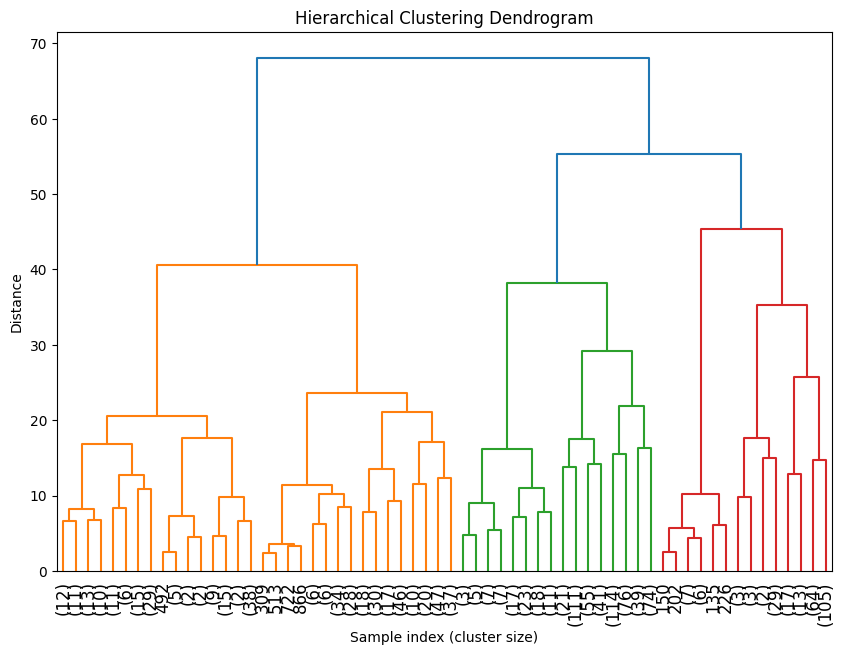

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
from IPython.display import display, Markdown
display(Markdown("### Data Preprocessing"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Check for missing values
print("Missing values before preprocessing:")
print(data.isnull().sum())
# Correct missing values using the median
data = data.fillna(data.median())
# Identify and remove duplicate rows
print("Duplicate rows before removal:", data.duplicated().sum())
data = data.drop_duplicates()
print("Duplicate rows after removal:", data.duplicated().sum())
display(Markdown("### Step 2.1: Hierarchical Clustering"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Standardize the numerical features
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)
# Perform hierarchical clustering to find a starting k
Z = linkage(data_scaled, method='ward')
# Plot the dendrogram
plt.figure(figsize=(10, 7))
dendrogram(Z, truncate_mode='level', p=5, leaf_rotation=90., leaf_font_size=12., show_contracted=True)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Sample index (cluster size)')
plt.ylabel('Distance')
plt.show()

In [6]:
from sklearn.cluster import KMeans
display(Markdown("### K-Means Clustering"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Initialize the KMeans model
k = 3
kmeans = KMeans(n_clusters=k, random_state=42)
# Fit the model to the data
kmeans.fit(data_scaled)
# Get the cluster labels and centroids
labels = kmeans.labels_
centroids = kmeans.cluster_centers_
# Display the cluster labels and centroids
print("Cluster labels:")
print(labels)
print("Cluster centroids:")
print(centroids)

### K-Means Clustering

Date: 2026-10-26

Student ID: abrgeb8774

Cluster labels:
[0 0 0 ... 2 0 2]
Cluster centroids:
[[-0.32072257  0.4964585  -0.49393216 -0.01698046 -0.04924648  0.11556021
   0.26525842  0.13179874  0.17006034 -0.40280258 -0.58077988 -0.53897811]
 [ 1.21438703 -0.61949768  1.12766266  0.20154051  0.46138232 -0.30311033
  -0.29490674  0.79521111 -0.89494415  0.67973493  0.04464944  0.32884569]
 [-0.61801805 -0.35240577 -0.18048807 -0.17527622 -0.38044732  0.08302953
  -0.22577894 -1.09036021  0.58843703  0.1019686   1.11863982  0.73959553]]


### Optimizing K-Means Clustering with Elbow Method

Date: 2026-10-26

Student ID: abrgeb8774

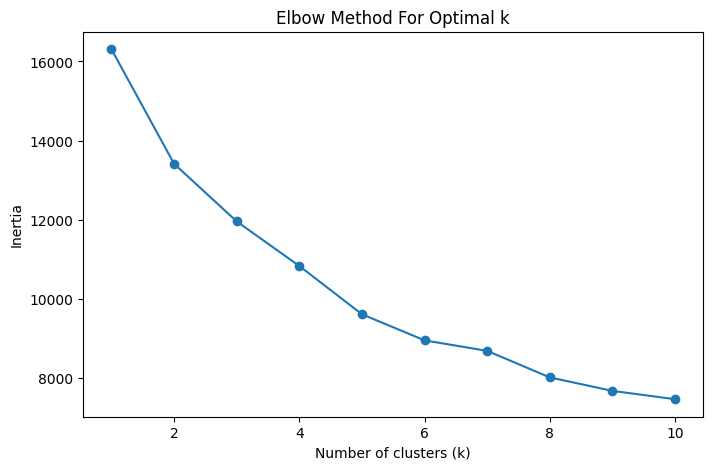

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
display(Markdown("### Optimizing K-Means Clustering with Elbow Method"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Use Elbow Method to find optimal k
inertia = []
k_values = range(1, 11)
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(data_scaled)
    inertia.append(kmeans.inertia_)
# Plot the Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.show()

### Optimizing K-Means Clustering with Silhouette Scores

Date: 2026-10-26

Student ID: abrgeb8774

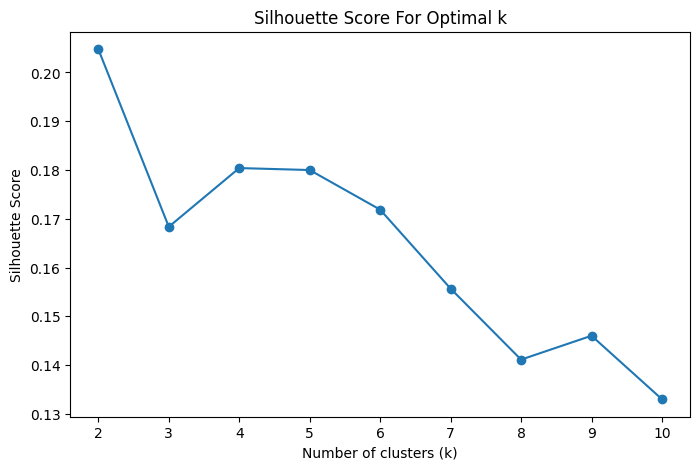

In [9]:
display(Markdown("### Optimizing K-Means Clustering with Silhouette Scores"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Silhouette Score
silhouette_scores = []
# Calculate the Silhouette Score to find optimal k
for k in k_values:
    if k > 1:
        kmeans = KMeans(n_clusters=k, random_state=42)
        kmeans.fit(data_scaled)
        score = silhouette_score(data_scaled, kmeans.labels_)
        silhouette_scores.append(score)
# Plot Silhouette Scores
plt.figure(figsize=(8, 5))
plt.plot(k_values[1:], silhouette_scores, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score For Optimal k')
plt.show()

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
display(Markdown("### Evaluate the Clustering"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Set the optimal number of clusters based on the plots
optimal_k = 2
# Refit the KMeans model using the optimal number of clusters
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
kmeans.fit(data_scaled)
# Get the cluster labels
labels = kmeans.labels_
# Calculate the Silhouette Score
score = silhouette_score(data_scaled, labels)
# Display the Silhouette Score
print(f"Optimal number of clusters (k): {optimal_k}")
print(f"Silhouette Score: {score:.4f}")

### Evaluate the Clustering

Date: 2026-10-26

Student ID: abrgeb8774

Optimal number of clusters (k): 2
Silhouette Score: 0.2048


### Visualize the Clustering Results

Date: 2026-10-26

Student ID: abrgeb8774

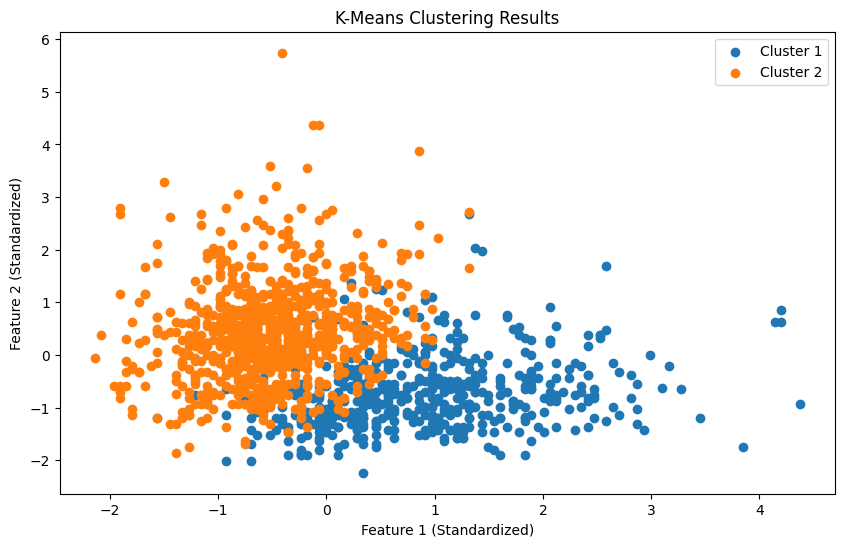

In [11]:
display(Markdown("### Visualize the Clustering Results"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Plot the clusters
plt.figure(figsize=(10, 6))
for i in range(optimal_k):
    cluster_points = data_scaled[labels == i]
    plt.scatter(cluster_points[:, 0], cluster_points[:, 1], label=f'Cluster {i + 1}')
# Add labels and title
plt.xlabel('Feature 1 (Standardized)')
plt.ylabel('Feature 2 (Standardized)')
plt.title('K-Means Clustering Results')
plt.legend()
plt.show()